<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS08/JS08_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

In [2]:
iris = load_iris()
X_raw = iris.data
y_true = iris.target

print("Shape:", X_raw.shape)
print("Fitur:", iris.feature_names)
print("Kelas asli:", iris.target_names)
print("Jumlah per kelas:", np.bincount(y_true))

Shape: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas asli: ['setosa' 'versicolor' 'virginica']
Jumlah per kelas: [50 50 50]


In [3]:
X = StandardScaler().fit_transform(X_raw)

In [4]:
hdb = hdbscan.HDBSCAN(min_cluster_size=5)
hdb.fit(X)
labels = hdb.labels_

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print("Label unik:", sorted(set(labels)))
print("Jumlah cluster:", n_clusters)
print("Jumlah noise  :", n_noise)

Label unik: [np.int64(-1), np.int64(0), np.int64(1)]
Jumlah cluster: 2
Jumlah noise  : 2


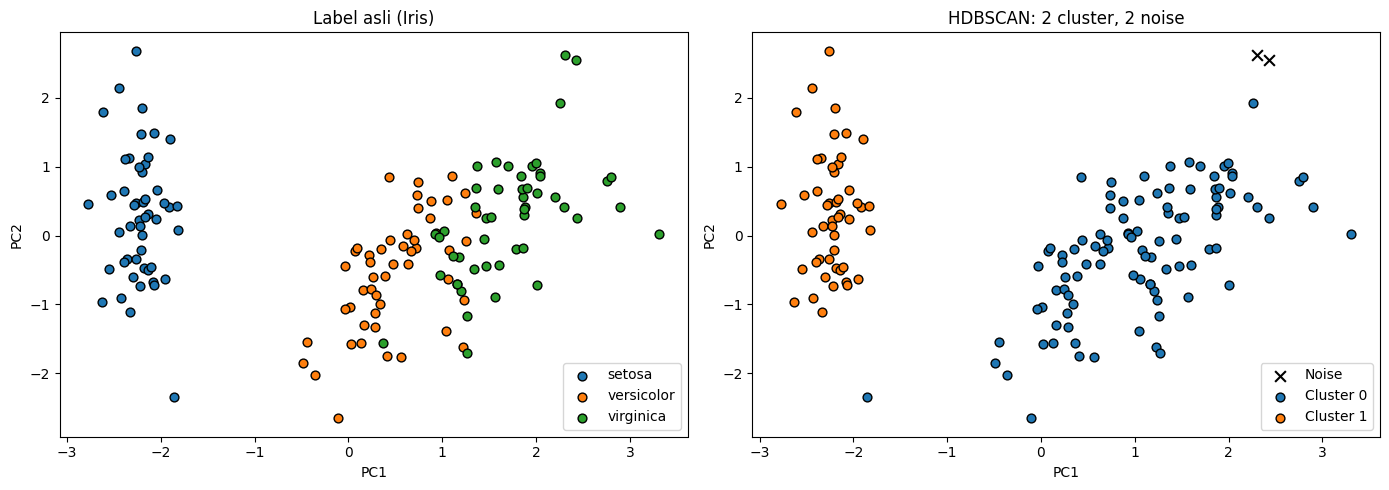

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for k, name in enumerate(iris.target_names):
    axes[0].scatter(X_pca[y_true == k, 0], X_pca[y_true == k, 1], label=name, s=40, edgecolor="k")
axes[0].set_title("Label asli (Iris)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

for k in sorted(set(labels)):
    mask = labels == k
    if k == -1:
        axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c="black", marker="x", s=60, label="Noise")
    else:
        axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=40, edgecolor="k", label=f"Cluster {k}")
axes[1].set_title(f"HDBSCAN: {n_clusters} cluster, {n_noise} noise")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
ari = adjusted_rand_score(y_true, labels)
nmi = normalized_mutual_info_score(y_true, labels)
print(f"Adjusted Rand Index (ARI)      : {ari:.4f}")
print(f"Normalized Mutual Info (NMI)   : {nmi:.4f}")

ct = pd.crosstab(pd.Series(iris.target_names[y_true], name="Spesies asli"),
                 pd.Series(labels, name="Cluster HDBSCAN"))
ct

Adjusted Rand Index (ARI)      : 0.5394
Normalized Mutual Info (NMI)   : 0.6778


Cluster HDBSCAN,-1,0,1
Spesies asli,,,
setosa,0,1,49
versicolor,0,50,0
virginica,2,48,0


In [7]:
for mcs in [3, 5, 10, 15, 20]:
    l = hdbscan.HDBSCAN(min_cluster_size=mcs).fit(X).labels_
    nc = len(set(l)) - (1 if -1 in l else 0)
    print(f"min_cluster_size={mcs:>2} | cluster={nc} | noise={(l == -1).sum()} | ARI={adjusted_rand_score(y_true, l):.3f}")

min_cluster_size= 3 | cluster=2 | noise=2 | ARI=0.539
min_cluster_size= 5 | cluster=2 | noise=2 | ARI=0.539
min_cluster_size=10 | cluster=2 | noise=2 | ARI=0.539
min_cluster_size=15 | cluster=2 | noise=4 | ARI=0.544
min_cluster_size=20 | cluster=2 | noise=6 | ARI=0.538


HDBSCAN belum sepenuhnya sesuai dengan label asli karena hanya menghasilkan 2 cluster, sedangkan dataset Iris memiliki 3 spesies. Setosa berhasil dipisahkan dengan baik, sedangkan versicolor dan virginica tergabung dalam satu cluster karena karakteristik keduanya mirip dan saling tumpang tindih. HDBSCAN mengelompokkan data berdasarkan kepadatan, sehingga kedua spesies tersebut sulit dipisahkan. Nilai ARI 0,56 dan NMI 0,72 menunjukkan hasil pengelompokan cukup sesuai, tetapi belum sempurna. Mengubah min_cluster_size juga belum berhasil menghasilkan 3 cluster.